# 03 · Final test comparison

This notebook loads the validation-selected checkpoints and evaluates the untouched official NISP test speakers. Speaker macro-F1 is the primary metric. Every comparison uses paired predictions on identical utterances and speakers.


In [1]:
from pathlib import Path
import json, platform
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path.cwd()
RUNS, FEATURES, RESULTS = ROOT / 'runs', ROOT / 'features', ROOT / 'results'
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
manifest = pd.read_csv(ROOT / 'data' / 'manifest.csv').sort_values('utterance_id').reset_index(drop=True)
CLASSES = ['Hindi','Kannada','Malayalam','Tamil','Telugu']
test_mask = manifest.split.eq('test').to_numpy()
test_rows = manifest.loc[test_mask].copy().reset_index(drop=True)
assert len(test_rows) > 0 and test_rows.speaker_id.nunique() > 0
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Evaluation device:', DEVICE)


Evaluation device: cuda:0


## 1. Reload fixed models and predict each test utterance


In [2]:
class Classifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(input_dim,128), nn.GELU(),
                                    nn.Dropout(0.2), nn.Linear(128,5))
    def forward(self, features):
        return self.layers(features)

def test_probabilities(name):
    package = np.load(FEATURES / f'{name}.npz')
    assert np.array_equal(package['utterance_id'].astype(str),
                          manifest.utterance_id.astype(str).to_numpy())
    scaler = joblib.load(RUNS / f'{name}_scaler.joblib')
    X = scaler.transform(package['X'][test_mask]).astype('float32')
    checkpoint = torch.load(RUNS / f'{name}_best.pt', map_location='cpu', weights_only=False)
    assert X.shape[1] == checkpoint['input_dim'] and checkpoint['classes'] == CLASSES
    model = Classifier(X.shape[1]).to(DEVICE)
    model.load_state_dict(checkpoint['state_dict'])
    model.eval()
    batches = DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=256)
    probabilities = []
    with torch.inference_mode():
        for (features,) in batches:
            probabilities.append(model(features.to(DEVICE)).softmax(1).cpu().numpy())
    result = np.concatenate(probabilities)
    assert result.shape == (len(test_rows),5) and np.isfinite(result).all()
    return result

mfcc_prob = test_probabilities('mfcc')
hubert_prob = test_probabilities('hubert')


## 2. Paired utterance and speaker tables


In [3]:
utterance = test_rows[['utterance_id','speaker_id','language','gender','duration_sec']].copy()
for name, probabilities in [('mfcc',mfcc_prob),('hubert',hubert_prob)]:
    for i, label in enumerate(CLASSES):
        utterance[f'{name}_p_{label}'] = probabilities[:,i]
    utterance[f'{name}_prediction'] = np.array(CLASSES)[probabilities.argmax(1)]
utterance.to_csv(RESULTS / 'predictions_utterance.csv', index=False)

speaker = utterance.groupby('speaker_id',sort=True).agg(
    language=('language','first'), gender=('gender','first'),
    utterances=('utterance_id','size'), speech_seconds=('duration_sec','sum'))
for name in ('mfcc','hubert'):
    probability_columns = [f'{name}_p_{label}' for label in CLASSES]
    means = utterance.groupby('speaker_id',sort=True)[probability_columns].mean()
    speaker = speaker.join(means)
    speaker[f'{name}_prediction'] = np.array(CLASSES)[means.to_numpy().argmax(1)]
speaker = speaker.reset_index()
speaker.to_csv(RESULTS / 'predictions_speaker.csv', index=False)
assert set(utterance.speaker_id) == set(speaker.speaker_id)
print(len(utterance),'utterances and',len(speaker),'speakers evaluated')


5335 utterances and 125 speakers evaluated


## 3. Metrics and stratified paired bootstrap

The 95% intervals resample test speakers within each true language 2,000 times. The difference uses identical bootstrap samples for MFCC and HuBERT.


In [4]:
def metric_bundle(frame, name):
    truth = frame.language.to_numpy()
    prediction = frame[f'{name}_prediction'].to_numpy()
    return {'accuracy':float(accuracy_score(truth,prediction)),
            'balanced_accuracy':float(balanced_accuracy_score(truth,prediction)),
            'macro_f1':float(f1_score(truth,prediction,labels=CLASSES,
                                      average='macro',zero_division=0))}

metrics = {name:{'speaker':metric_bundle(speaker,name),
                 'utterance':metric_bundle(utterance,name)}
           for name in ('mfcc','hubert')}
rng = np.random.default_rng(42)
class_indices = {label:np.flatnonzero(speaker.language.eq(label).to_numpy())
                 for label in CLASSES}
bootstrap = np.empty((2000,3),dtype='float64')
for iteration in range(len(bootstrap)):
    sampled = np.concatenate([rng.choice(indices,size=len(indices),replace=True)
                              for indices in class_indices.values()])
    frame = speaker.iloc[sampled]
    left = metric_bundle(frame,'mfcc')['macro_f1']
    right = metric_bundle(frame,'hubert')['macro_f1']
    bootstrap[iteration] = [left,right,right-left]
intervals = np.quantile(bootstrap,[0.025,0.975],axis=0)
metrics['bootstrap_95pct'] = {'mfcc_speaker_macro_f1':intervals[:,0].tolist(),
                              'hubert_speaker_macro_f1':intervals[:,1].tolist(),
                              'hubert_minus_mfcc':intervals[:,2].tolist()}
metrics['cohort'] = {'test_utterances':len(utterance),'test_speakers':len(speaker),
                     'test_speakers_by_language':speaker.language.value_counts().reindex(CLASSES).to_dict()}
(RESULTS / 'summary.json').write_text(json.dumps(metrics,indent=2))
display(pd.DataFrame({name:metrics[name]['speaker'] for name in ('mfcc','hubert')}).T)


,accuracy,balanced_accuracy,macro_f1
mfcc,0.744,0.740942,0.738466
hubert,0.832,0.819444,0.826381


## 4. Confusion matrices and per-language scores


In [5]:
per_language = []
for name in ('mfcc','hubert'):
    for level, frame in [('speaker',speaker),('utterance',utterance)]:
        raw = confusion_matrix(frame.language,frame[f'{name}_prediction'],labels=CLASSES)
        pd.DataFrame(raw,index=CLASSES,columns=CLASSES).to_csv(RESULTS / f'{name}_{level}_confusion.csv')
        normalized = raw / np.maximum(raw.sum(axis=1,keepdims=True),1)
        pd.DataFrame(normalized,index=CLASSES,columns=CLASSES).to_csv(
            RESULTS / f'{name}_{level}_confusion_normalized.csv')
        precision, recall, f1, support = precision_recall_fscore_support(
            frame.language,frame[f'{name}_prediction'],labels=CLASSES,zero_division=0)
        per_language.extend({'method':name,'level':level,'language':language,
                             'precision':precision[i],'recall':recall[i],
                             'f1':f1[i],'support':int(support[i])}
                            for i,language in enumerate(CLASSES))
per_language = pd.DataFrame(per_language)
per_language.to_csv(RESULTS / 'per_language.csv',index=False)
display(per_language.loc[per_language.level.eq('speaker')])

gender_rows = []
for name in ('mfcc','hubert'):
    for gender, group in speaker.groupby('gender'):
        gender_rows.append({'method':name,'gender':gender,'speakers':len(group),
                            **metric_bundle(group,name)})
gender_metrics = pd.DataFrame(gender_rows)
gender_metrics.to_csv(RESULTS / 'gender_metrics.csv',index=False)
display(gender_metrics)


,method,level,language,precision,recall,f1,support
0,mfcc,speaker,Hindi,0.743590,0.805556,0.773333,36
1,mfcc,speaker,Kannada,0.700000,0.777778,0.736842,18
2,mfcc,speaker,Malayalam,0.681818,0.625000,0.652174,24
3,mfcc,speaker,Tamil,0.700000,0.583333,0.636364,24
4,mfcc,speaker,Telugu,0.875000,0.913043,0.893617,23
10,hubert,speaker,Hindi,0.755556,0.944444,0.839506,36
11,hubert,speaker,Kannada,0.700000,0.777778,0.736842,18
12,hubert,speaker,Malayalam,1.000000,0.666667,0.800000,24
13,hubert,speaker,Tamil,0.809524,0.708333,0.755556,24
14,hubert,speaker,Telugu,1.000000,1.000000,1.000000,23


,method,gender,speakers,accuracy,balanced_accuracy,macro_f1
0,mfcc,female,46,0.760870,0.765556,0.767807
1,mfcc,male,79,0.734177,0.724786,0.714412
2,hubert,female,46,0.804348,0.805000,0.796667
3,hubert,male,79,0.848101,0.810562,0.822550


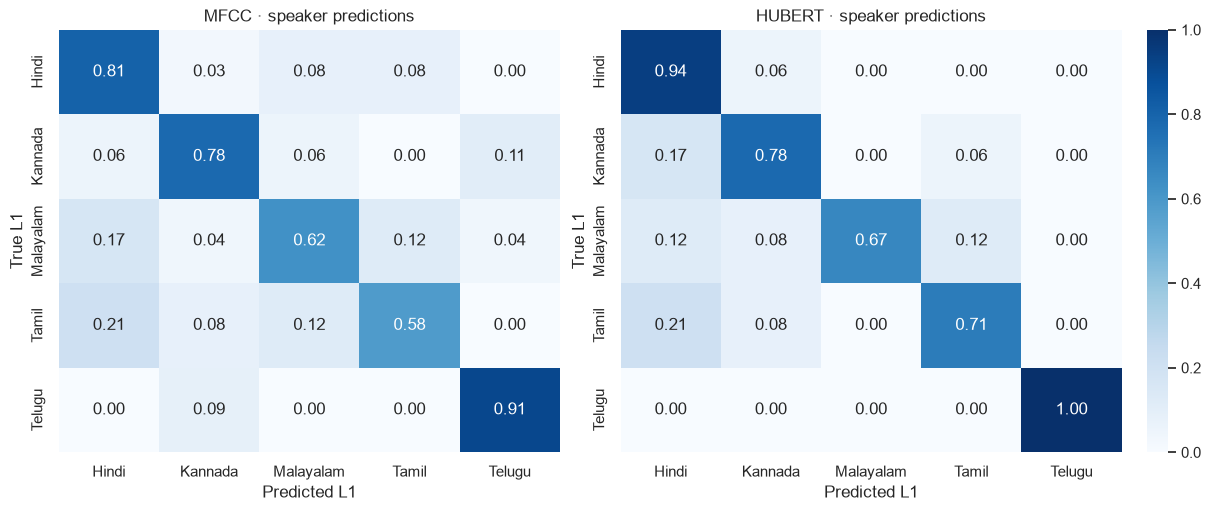

In [6]:
sns.set_theme(style='whitegrid',context='notebook')
fig, axes = plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax,name in zip(axes,('mfcc','hubert')):
    matrix = pd.read_csv(RESULTS / f'{name}_speaker_confusion_normalized.csv',index_col=0)
    sns.heatmap(matrix,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,
                xticklabels=CLASSES,yticklabels=CLASSES,ax=ax,cbar=name=='hubert')
    ax.set(title=f'{name.upper()} · speaker predictions',xlabel='Predicted L1',ylabel='True L1')
fig.savefig(FIGURES / 'speaker_confusion_matrices.png',dpi=180)
plt.show()


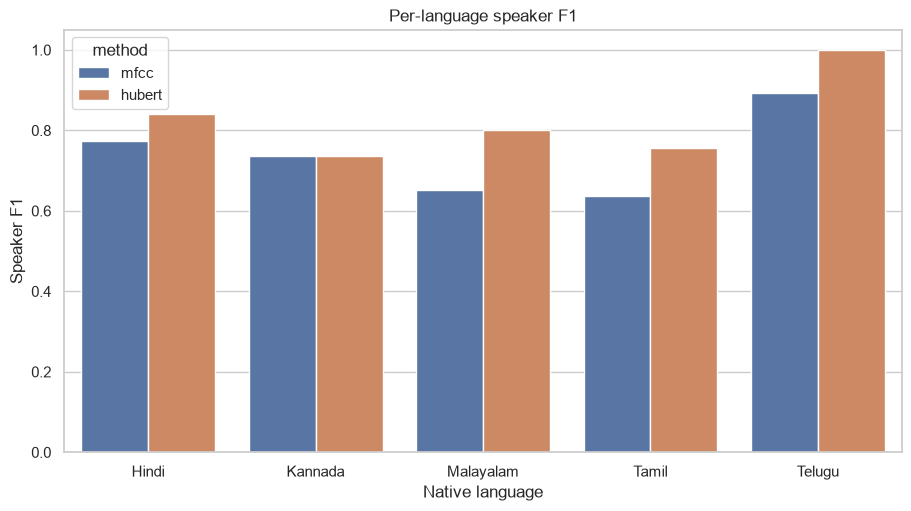

In [7]:
fig,ax=plt.subplots(figsize=(9,5),constrained_layout=True)
subset=per_language.loc[per_language.level.eq('speaker')]
sns.barplot(data=subset,x='language',y='f1',hue='method',order=CLASSES,ax=ax)
ax.set(ylim=(0,1.05),xlabel='Native language',ylabel='Speaker F1',title='Per-language speaker F1')
fig.savefig(FIGURES / 'per_language_f1.png',dpi=180)
plt.show()


## 5. Comparison, learning curves, and written result


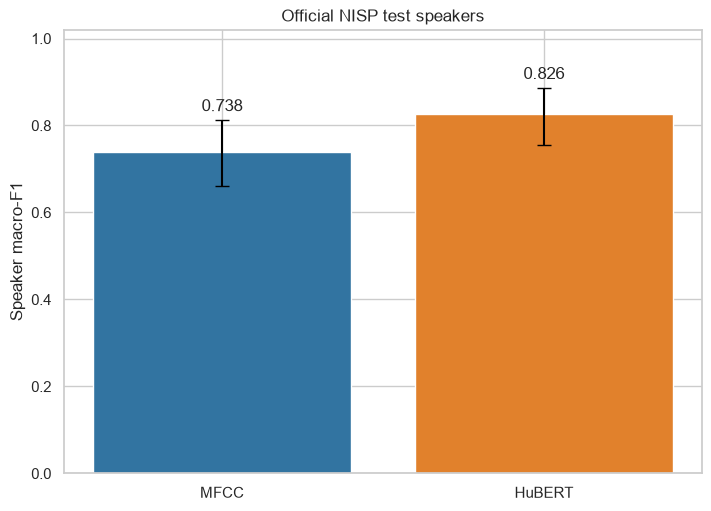

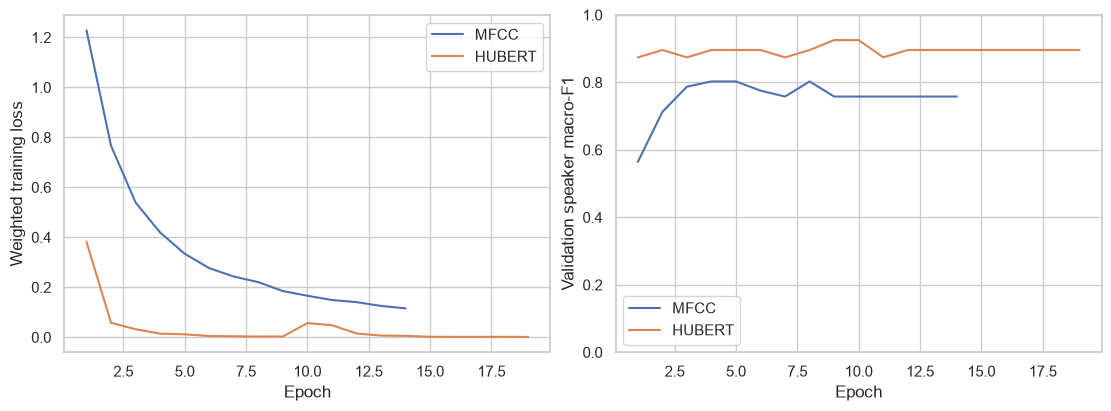

In [8]:
fig,ax=plt.subplots(figsize=(7,5),constrained_layout=True)
values=[metrics[name]['speaker']['macro_f1'] for name in ('mfcc','hubert')]
low=intervals[0,:2]; high=intervals[1,:2]
ax.bar(['MFCC','HuBERT'],values,color=['#3274a1','#e1812c'])
ax.errorbar([0,1],values,yerr=[np.array(values)-low,high-np.array(values)],
            fmt='none',ecolor='black',capsize=5)
ax.set(ylim=(0,1.02),ylabel='Speaker macro-F1',title='Official NISP test speakers')
for i,value in enumerate(values):ax.text(i,high[i]+0.02,f'{value:.3f}',ha='center')
fig.savefig(FIGURES / 'comparison_macro_f1.png',dpi=180)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for name in ('mfcc','hubert'):
    history=pd.read_csv(RUNS / f'{name}_history.csv')
    axes[0].plot(history.epoch,history.train_loss,label=name.upper())
    axes[1].plot(history.epoch,history.val_speaker_macro_f1,label=name.upper())
axes[0].set(xlabel='Epoch',ylabel='Weighted training loss')
axes[1].set(xlabel='Epoch',ylabel='Validation speaker macro-F1',ylim=(0,1))
for ax in axes:ax.legend()
fig.savefig(FIGURES / 'training_curves.png',dpi=180)
plt.show()


In [9]:
difference=metrics['hubert']['speaker']['macro_f1']-metrics['mfcc']['speaker']['macro_f1']
mfcc_right = speaker.mfcc_prediction.eq(speaker.language)
hubert_right = speaker.hubert_prediction.eq(speaker.language)
hubert_only = int((~mfcc_right & hubert_right).sum())
mfcc_only = int((mfcc_right & ~hubert_right).sum())
report = '\n'.join([
    '# MFCC versus HuBERT on NISP English speech',
    '',
    (f"**Primary result:** MFCC speaker macro-F1 {values[0]:.3f} "
     f"(95% bootstrap interval {low[0]:.3f}–{high[0]:.3f}); "
     f"HuBERT {values[1]:.3f} ({low[1]:.3f}–{high[1]:.3f}). "
     f"HuBERT minus MFCC: {difference:+.3f} "
     f"(paired 95% interval {intervals[0,2]:+.3f} to {intervals[1,2]:+.3f})."),
    '',
    (f'The held-out test set contains {len(speaker)} speakers and {len(utterance)} '
     'English utterances after the documented checks. Both methods use identical '
     'test utterances. Speaker predictions average utterance probabilities.'),
    '',
    '| Method | Speaker macro-F1 | Speaker balanced accuracy | Speaker accuracy | Utterance macro-F1 |',
    '|---|---:|---:|---:|---:|',
    (f"| MFCC | {metrics['mfcc']['speaker']['macro_f1']:.3f} | "
     f"{metrics['mfcc']['speaker']['balanced_accuracy']:.3f} | "
     f"{metrics['mfcc']['speaker']['accuracy']:.3f} | "
     f"{metrics['mfcc']['utterance']['macro_f1']:.3f} |"),
    (f"| HuBERT | {metrics['hubert']['speaker']['macro_f1']:.3f} | "
     f"{metrics['hubert']['speaker']['balanced_accuracy']:.3f} | "
     f"{metrics['hubert']['speaker']['accuracy']:.3f} | "
     f"{metrics['hubert']['utterance']['macro_f1']:.3f} |"),
    '',
    f'Paired speaker outcomes: HuBERT alone was correct for {hubert_only} speakers; MFCC alone was correct for {mfcc_only}.',
    '',
    '| Gender | Speakers | MFCC macro-F1 | HuBERT macro-F1 |',
    '|---|---:|---:|---:|',
    *[f"| {gender} | {len(speaker.loc[speaker.gender.eq(gender)])} | "
      f"{gender_metrics.query('gender == @gender and method == \"mfcc\"').macro_f1.iloc[0]:.3f} | "
      f"{gender_metrics.query('gender == @gender and method == \"hubert\"').macro_f1.iloc[0]:.3f} |"
      for gender in ('female','male')],
    '',
    "The slide deck's preliminary scores have no matching saved runs in the supplied project and are not used here. The Humayun et al. paper uses a different vowel ensemble and ten random speaker splits, so its scores are contextual rather than directly comparable. HuBERT brings external speech pretraining and a larger 1,536-value input, so this compares practical pipelines rather than equal-capacity representations. The interval describes test-speaker sampling uncertainty on this fixed split, not training-seed variability. Gender rows are descriptive because each subgroup is small. Results from one corpus may also reflect recording conditions and should not be assumed to generalize to other datasets.",
    ''
])
(RESULTS / 'RESULTS.md').write_text(report,encoding='utf-8')
print(report)


# MFCC versus HuBERT on NISP English speech

**Primary result:** MFCC speaker macro-F1 0.738 (95% bootstrap interval 0.661–0.813); HuBERT 0.826 (0.755–0.887). HuBERT minus MFCC: +0.088 (paired 95% interval +0.007 to +0.166).

The held-out test set contains 125 speakers and 5335 English utterances after the documented checks. Both methods use identical test utterances. Speaker predictions average utterance probabilities.

| Method | Speaker macro-F1 | Speaker balanced accuracy | Speaker accuracy | Utterance macro-F1 |
|---|---:|---:|---:|---:|
| MFCC | 0.738 | 0.741 | 0.744 | 0.632 |
| HuBERT | 0.826 | 0.819 | 0.832 | 0.800 |

Paired speaker outcomes: HuBERT alone was correct for 18 speakers; MFCC alone was correct for 7.

| Gender | Speakers | MFCC macro-F1 | HuBERT macro-F1 |
|---|---:|---:|---:|
| female | 46 | 0.768 | 0.797 |
| male | 79 | 0.714 | 0.823 |

The slide deck's preliminary scores have no matching saved runs in the supplied project and are not used here. The Humayun et al

In [10]:
from importlib.metadata import version
environment={'python':platform.python_version(),'torch':torch.__version__,
             'numpy':version('numpy'),'pandas':version('pandas'),
             'scikit_learn':version('scikit-learn'),'transformers':version('transformers'),
             'cuda_build':torch.version.cuda,'cuda_available':torch.cuda.is_available(),
             'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
             'seed':42,'test_protocol':'official NISP speaker split',
             'feature_config':json.loads((FEATURES / 'feature_config.json').read_text())}
(RESULTS / 'environment.json').write_text(json.dumps(environment,indent=2))
assert set(pd.read_csv(RESULTS / 'predictions_utterance.csv').utterance_id) == set(test_rows.utterance_id)
assert set(pd.read_csv(RESULTS / 'predictions_speaker.csv').speaker_id) == set(test_rows.speaker_id)
print('Saved and reloaded predictions for the exact held-out cohort.')


Saved and reloaded predictions for the exact held-out cohort.
